<a href="https://colab.research.google.com/github/KatziNibir/Hi/blob/main/U_Net_for_Image_Segmentation_From_Scratch_Using_TensorFlow_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Code Breakdown

- [1 - Packages](#1)
- [2 - Helper Functions for Data Processing](#2)
    - [2.1 - Load Data](#2.1)
    - [2.2 - Pre-Process Data](#2.2)
- [3 - Helper Functions for U-Net Architecture](#3)
    - [3.1 - U-Net Encoder Block](#3.1)
    - [3.2 - U-Net Decoder Block](#3.2)
    - [3.3 - Compile U-Net Blocks](#3.3)
- [4 - Executing above Functions to Train the Model](#4)
    - [4.1 - Load and View Data](#4.1)
    - [4.2 - Process Data](#4.2)
    - [4.3 - Split Train and Test](#4.3)
    - [4.4 - Build U-Net Architecture](#4.4)
    - [4.5 - Compile and Run Model](#4.5)
- [5 - Evaluate Results](#5)
    - [5.1 - Bias-Variance Check](#5.1)
    - [5.2 - View Predicted Segmentations](#5.2)

<a name='1'></a>
# 1 - Packages

In [ ]:
# for data load
import os

# for reading and processing images
import imageio
from PIL import Image

# for visualizations
import matplotlib.pyplot as plt

import numpy as np # for using np arrays

# for bulding and running deep learning model
import tensorflow as tf
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.layers import Conv2DTranspose
from tensorflow.keras.layers import concatenate
from tensorflow.keras.losses import binary_crossentropy
from sklearn.model_selection import train_test_split

<a name='2'></a>
# 2 - Helper Functions for Data Processing

<a name='2.1'></a>
## 2.1 - Load Data
* the masked images are stored as png, unmasked (original) as jpg
* the names of these 2 are same so for getting the right sample we can just sort the 2 lists

In [ ]:
def LoadData (path1, path2):
    """
    Looks for relevant filenames in the shared path
    Returns 2 lists for original and masked files respectively

    """
    # Read the images folder like a list
    image_dataset = os.listdir(path1)
    mask_dataset = os.listdir(path2)

    # Make a list for images and masks filenames
    orig_img = []
    mask_img = []
    for file in image_dataset:
        orig_img.append(file)
    for file in mask_dataset:
        mask_img.append(file)

    # Sort the lists to get both of them in same order (the dataset has exactly the same name for images and corresponding masks)
    orig_img.sort()
    mask_img.sort()

    return orig_img, mask_img

<a name='2.2'></a>
## 2.2 - Pre-Process Data

In [ ]:
def PreprocessData(img, mask, target_shape_img, target_shape_mask, path1, path2):
    """
    Processes the images and mask present in the shared list and path
    Returns a NumPy dataset with images as 3-D arrays of desired size
    Please note the masks in this dataset have only one channel
    """
    # Pull the relevant dimensions for image and mask
    m = len(img)                     # number of images
    i_h,i_w,i_c = target_shape_img   # pull height, width, and channels of image
    m_h,m_w,m_c = target_shape_mask  # pull height, width, and channels of mask

    # Define X and Y as number of images along with shape of one image
    X = np.zeros((m,i_h,i_w,i_c), dtype=np.float32)
    y = np.zeros((m,m_h,m_w,m_c), dtype=np.int32)

    # Resize images and masks
    for file in img:
        # convert image into an array of desired shape (3 channels)
        index = img.index(file)
        path = os.path.join(path1, file)
        single_img = Image.open(path).convert('RGB')
        single_img = single_img.resize((i_h,i_w))
        single_img = np.reshape(single_img,(i_h,i_w,i_c))
        single_img = single_img/256.
        X[index] = single_img

        # convert mask into an array of desired shape (1 channel)
        single_mask_ind = mask[index]
        path = os.path.join(path2, single_mask_ind)
        single_mask = Image.open(path)
        single_mask = single_mask.resize((m_h, m_w))
        single_mask = np.reshape(single_mask,(m_h,m_w,m_c))
        single_mask = single_mask - 1 # to ensure classes #s start from 0
        y[index] = single_mask
    return X, y

<a name='3'></a>
#3 - Constructing the U-Net Architecture


<a name='3.1'></a>
## 3.1 - U-Net Encoder Block

In [ ]:
def EncoderMiniBlock(inputs, n_filters=32, dropout_prob=0.3, max_pooling=True):
    """
    This block uses multiple convolution layers, max pool, relu activation to create an architecture for learning.
    Dropout can be added for regularization to prevent overfitting.
    The block returns the activation values for next layer along with a skip connection which will be used in the decoder
    """
    # Add 2 Conv Layers with relu activation and HeNormal initialization using TensorFlow
    # Proper initialization prevents from the problem of exploding and vanishing gradients
    # 'Same' padding will pad the input to conv layer such that the output has the same height and width (hence, is not reduced in size)
    conv = Conv2D(n_filters,
                  3,   # Kernel size
                  activation='relu',
                  padding='same',
                  kernel_initializer='HeNormal')(inputs)
    conv = Conv2D(n_filters,
                  3,   # Kernel size
                  activation='relu',
                  padding='same',
                  kernel_initializer='HeNormal')(conv)

    # Batch Normalization will normalize the output of the last layer based on the batch's mean and standard deviation
    conv = BatchNormalization()(conv, training=False)

    # In case of overfitting, dropout will regularize the loss and gradient computation to shrink the influence of weights on output
    if dropout_prob > 0:
        conv = tf.keras.layers.Dropout(dropout_prob)(conv)

    # Pooling reduces the size of the image while keeping the number of channels same
    # Pooling has been kept as optional as the last encoder layer does not use pooling (hence, makes the encoder block flexible to use)
    # Below, Max pooling considers the maximum of the input slice for output computation and uses stride of 2 to traverse across input image
    if max_pooling:
        next_layer = tf.keras.layers.MaxPooling2D(pool_size = (2,2))(conv)
    else:
        next_layer = conv

    # skip connection (without max pooling) will be input to the decoder layer to prevent information loss during transpose convolutions
    skip_connection = conv

    return next_layer, skip_connection

<a name='3.2'></a>
## 3.2 - U-Net Decoder Block

In [ ]:
def DecoderMiniBlock(prev_layer_input, skip_layer_input, n_filters=32):
    """
    Decoder Block first uses transpose convolution to upscale the image to a bigger size and then,
    merges the result with skip layer results from encoder block
    Adding 2 convolutions with 'same' padding helps further increase the depth of the network for better predictions
    The function returns the decoded layer output
    """
    # Start with a transpose convolution layer to first increase the size of the image
    up = Conv2DTranspose(
                 n_filters,
                 (3,3),    # Kernel size
                 strides=(2,2),
                 padding='same')(prev_layer_input)

    # Merge the skip connection from previous block to prevent information loss
    merge = concatenate([up, skip_layer_input], axis=3)

    # Add 2 Conv Layers with relu activation and HeNormal initialization for further processing
    # The parameters for the function are similar to encoder
    conv = Conv2D(n_filters,
                 3,     # Kernel size
                 activation='relu',
                 padding='same',
                 kernel_initializer='HeNormal')(merge)
    conv = Conv2D(n_filters,
                 3,   # Kernel size
                 activation='relu',
                 padding='same',
                 kernel_initializer='HeNormal')(conv)
    return conv

<a name='3.3'></a>
## 3.3 - Compile U-Net Blocks

In [ ]:
def UNetCompiled(input_size=(128, 128, 3), n_filters=32, n_classes=3):
   """
   Combine both encoder and decoder blocks according to the U-Net research paper
   Return the model as output
   """
    # Input size represent the size of 1 image (the size used for pre-processing)
    inputs = Input(input_size)

    # Encoder includes multiple convolutional mini blocks with different maxpooling, dropout and filter parameters
    # Observe that the filters are increasing as we go deeper into the network which will increasse the # channels of the image
    cblock1 = EncoderMiniBlock(inputs, n_filters,dropout_prob=0, max_pooling=True)
    cblock2 = EncoderMiniBlock(cblock1[0],n_filters*2,dropout_prob=0, max_pooling=True)
    cblock3 = EncoderMiniBlock(cblock2[0], n_filters*4,dropout_prob=0, max_pooling=True)
    cblock4 = EncoderMiniBlock(cblock3[0], n_filters*8,dropout_prob=0.3, max_pooling=True)
    cblock5 = EncoderMiniBlock(cblock4[0], n_filters*16, dropout_prob=0.3, max_pooling=False)

    # Decoder includes multiple mini blocks with decreasing number of filters
    # Observe the skip connections from the encoder are given as input to the decoder
    # Recall the 2nd output of encoder block was skip connection, hence cblockn[1] is used
    ublock6 = DecoderMiniBlock(cblock5[0], cblock4[1],  n_filters * 8)
    ublock7 = DecoderMiniBlock(ublock6, cblock3[1],  n_filters * 4)
    ublock8 = DecoderMiniBlock(ublock7, cblock2[1],  n_filters * 2)
    ublock9 = DecoderMiniBlock(ublock8, cblock1[1],  n_filters)

    # Complete the model with 1 3x3 convolution layer (Same as the prev Conv Layers)
    # Followed by a 1x1 Conv layer to get the image to the desired size.
    # Observe the number of channels will be equal to number of output classes
    conv9 = Conv2D(n_filters,
                 3,
                 activation='relu',
                 padding='same',
                 kernel_initializer='he_normal')(ublock9)

    conv10 = Conv2D(n_classes, 1, padding='same')(conv9)

    # Define the model
    model = tf.keras.Model(inputs=inputs, outputs=conv10)

    return model

<a name='4'></a>
# 4 - Executing above Functions to Train the Model

<a name='4.4'></a>
## 4.4 - Build U-Net Architecture

In [ ]:
# Call the helper function for defining the layers for the model, given the input image size
unet = UNetCompiled(input_size=(128,128,3), n_filters=32, n_classes=3)

In [ ]:
# Check the summary to better interpret how the output dimensions change in each layer
unet.summary()

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 128, 128, 3) 0                                            
__________________________________________________________________________________________________
conv2d (Conv2D)                 (None, 128, 128, 32) 896         input_1[0][0]                    
__________________________________________________________________________________________________
conv2d_1 (Conv2D)               (None, 128, 128, 32) 9248        conv2d[0][0]                     
__________________________________________________________________________________________________
batch_normalization (BatchNorma (None, 128, 128, 32) 128         conv2d_1[0][0]                   
______________________________________________________________________________________________

<a name='4.5'></a>
## 4.5 - Compile and Run Model

In [ ]:
# There are multiple optimizers, loss functions and metrics that can be used to compile multi-class segmentation models
# Ideally, try different options to get the best accuracy
unet.compile(optimizer=tf.keras.optimizers.Adam(),
             loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
# Cleaned: Removed the original supervised 20-epoch training loop

Epoch 1/20
185/185 [==============================] - 3177s 17s/step - loss: 0.7669 - accuracy: 0.6656 - val_loss: 0.6085 - val_accuracy: 0.7550
Epoch 2/20
185/185 [==============================] - 3177s 17s/step - loss: 0.5510 - accuracy: 0.7811 - val_loss: 0.4746 - val_accuracy: 0.8169
Epoch 3/20
185/185 [==============================] - 3171s 17s/step - loss: 0.4507 - accuracy: 0.8266 - val_loss: 0.4812 - val_accuracy: 0.8157
Epoch 4/20
185/185 [==============================] - 3210s 17s/step - loss: 0.3991 - accuracy: 0.8475 - val_loss: 0.3889 - val_accuracy: 0.8493
Epoch 5/20
185/185 [==============================] - 3193s 17s/step - loss: 0.3745 - accuracy: 0.8578 - val_loss: 0.3565 - val_accuracy: 0.8643
Epoch 6/20
185/185 [==============================] - 3193s 17s/step - loss: 0.3408 - accuracy: 0.8707 - val_loss: 0.3621 - val_accuracy: 0.8596
Epoch 7/20
185/185 [==============================] - 3190s 17s/step - loss: 0.3322 - accuracy: 0.8747 - val_loss: 0.3892 - val_ac

<a name='5'></a>
# 5 - Evaluate Model Results

<a name='5.1'></a>
## 5.1 - Bias Variance Check

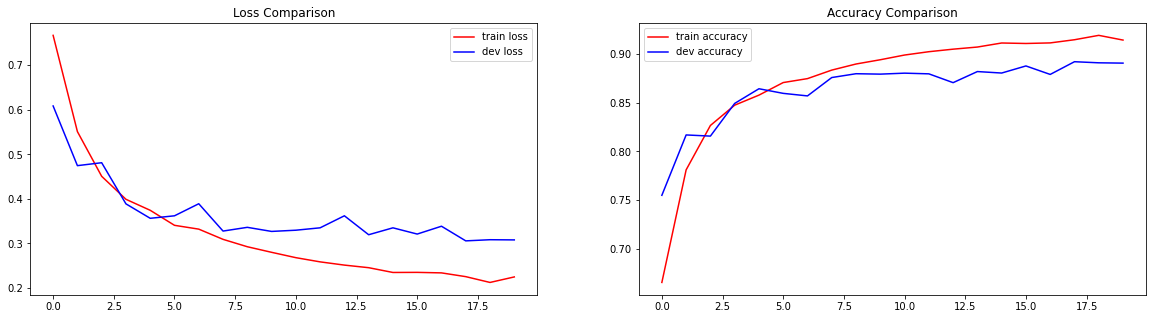

In [ ]:


# Cleaned: Removed Oxford IIIT Pet evaluation visualization code

<a name='5.2'></a>
## 5.2 - View Predicted Segmentations

In [ ]:
# Cleaned: Removed evaluation metrics execution

47/47 [==============================] - 194s 4s/step - loss: 0.3081 - accuracy: 0.8906


[0.3080694079399109, 0.8905980587005615]

In [ ]:
# Cleaned: Removed supervised visualization helper

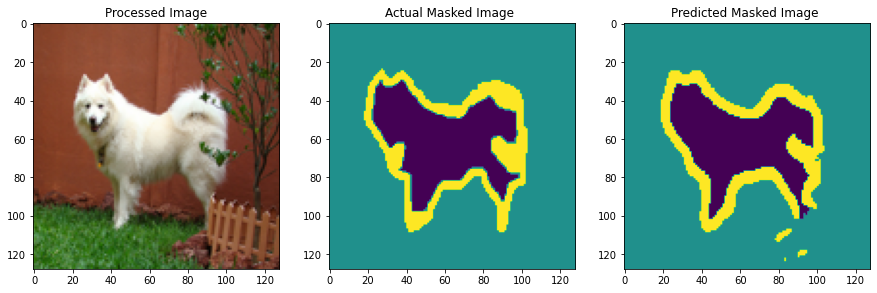

In [ ]:
# Cleaned: Removed test sample index visualizer

```markdown
# 6 - Semi-Supervised Few-Shot Adaptations (Industrial Defect Segmentation)

In industrial defect detection, labeled samples are rare. We can utilize a **Semi-Supervised Consistency Regularization** approach. Below we define:
1. A **Dice Loss** function (highly recommended for highly imbalanced industrial defects).
2. A **Teacher-Student Consistency Loop** helper to compute consistency loss on unlabeled images.
```

In [ ]:
import tensorflow as tf

def dice_loss(y_true, y_pred):
    """
    Computes multi-class Dice Loss to handle class imbalance in defect detection.
    """
    y_true = tf.one_hot(tf.cast(y_true[..., 0], tf.int32), depth=3)
    y_pred = tf.nn.softmax(y_pred, axis=-1)

    numerator = 2.0 * tf.reduce_sum(y_true * y_pred, axis=[1, 2])
    denominator = tf.reduce_sum(y_true + y_pred, axis=[1, 2])

    dice = (numerator + 1e-5) / (denominator + 1e-5)
    return 1.0 - tf.reduce_mean(dice)

def consistency_loss(student_logits, teacher_logits):
    """
    Computes MSE consistency loss between student and teacher predictions
    on unlabeled industrial images.
    """
    student_probs = tf.nn.softmax(student_logits, axis=-1)
    teacher_probs = tf.nn.softmax(teacher_logits, axis=-1)
    return tf.reduce_mean(tf.square(student_probs - teacher_probs))

```markdown
### Custom Semi-Supervised Training Step

Below is a template of how you can train your U-Net using a custom `tf.GradientTape` loop to update the Student model using both Supervised Loss (on your few labeled samples) and Consistency Loss (on your unlabeled samples).
```

In [ ]:
# Instantiating Student and Teacher U-Nets
student_model = UNetCompiled(input_size=(128,128,3), n_filters=32, n_classes=3)
teacher_model = UNetCompiled(input_size=(128,128,3), n_filters=32, n_classes=3)

# Keep teacher weights synchronized at the start
teacher_model.set_weights(student_model.get_weights())

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

@tf.function
def train_step_semi_supervised(x_labeled, y_labeled, x_unlabeled, ema_alpha=0.99):
    """
    One training step using Mean-Teacher Consistency Regularization.
    """
    with tf.GradientTape() as tape:
        # Forward pass on labeled data (Student)
        student_labeled_logits = student_model(x_labeled, training=True)
        sup_loss = dice_loss(y_labeled, student_labeled_logits)

        # Forward pass on unlabeled data (Student & Teacher)
        student_unlabeled_logits = student_model(x_unlabeled, training=True)
        teacher_unlabeled_logits = teacher_model(x_unlabeled, training=False)

        # Unsupervised consistency loss
        unsup_loss = consistency_loss(student_unlabeled_logits, teacher_unlabeled_logits)

        # Total Semi-Supervised Loss
        total_loss = sup_loss + 0.5 * unsup_loss

    # Update Student Weights
    gradients = tape.gradient(total_loss, student_model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, student_model.trainable_variables))

    # Exponential Moving Average (EMA) update for Teacher Weights
    for t_var, s_var in zip(teacher_model.trainable_variables, student_model.trainable_variables):
        t_var.assign(ema_alpha * t_var + (1.0 - ema_alpha) * s_var)

    return total_loss, sup_loss, unsup_loss

```markdown
## 6.1 - Data Augmentation Pipeline for Semi-Supervised Segmentation

For few-shot learning, strong augmentations are vital to prevent overfitting. Below, we create a function that applies:
1. **Joint spatial augmentations** (flips and rotations) to both images and masks.
2. **Intensity augmentations** (brightness, contrast, and noise) to the images only.
```

In [1]:
import tensorflow as tf

@tf.function
def augment_pair(image, mask, seed=42):
    """
    Applies identical spatial transformations to both the image and the mask,
    followed by intensity transformations to the image alone.
    """
    # Set deterministic seeds to ensure the same random transforms apply to image and mask
    rng_seed = tf.random.experimental.stateless_split(tf.random.uniform(shape=[2], minval=0, maxval=10000, dtype=tf.int32), num=3)

    # 1. Random Flips (Horizontal & Vertical)
    image = tf.image.stateless_random_flip_left_right(image, seed=rng_seed[0])
    mask = tf.image.stateless_random_flip_left_right(mask, seed=rng_seed[0])

    image = tf.image.stateless_random_flip_up_down(image, seed=rng_seed[1])
    mask = tf.image.stateless_random_flip_up_down(mask, seed=rng_seed[1])

    # 2. Random 90-degree Rotations
    rot_factor = tf.random.stateless_uniform(shape=[], seed=rng_seed[2], minval=0, maxval=4, dtype=tf.int32)
    image = tf.image.rot90(image, k=rot_factor)
    mask = tf.image.rot90(mask, k=rot_factor)

    # 3. Intensity / Color augmentations on the image only
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.clip_by_value(image, 0.0, 1.0) # Ensure values stay in [0, 1]

    return image, mask

@tf.function
def augment_unlabeled(image):
    """
    Applies intensity and spatial transformations to unlabeled images to construct
    perturbed inputs for consistency regularization.
    """
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_brightness(image, max_delta=0.25)
    image = tf.image.random_contrast(image, lower=0.7, upper=1.3)
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image

```markdown
## 6.2 - Creating the `tf.data.Dataset` Pipeline

We will construct two separate datasets:
1. **Labeled Dataset**: Applies spatial and color augmentations to both images and masks.
2. **Unlabeled Dataset**: Applies intensity and spatial perturbations to raw images.

Finally, we zip them together so that each iteration yields a batch of labeled images, labeled masks, and unlabeled images.
```

In [ ]:
def create_semi_supervised_dataset(X_labeled, y_labeled, X_unlabeled, batch_size=16):
    """
    Creates a zipped dataset returning (labeled_batch, unlabeled_batch) pairs.
    """
    # Labeled stream
    labeled_ds = tf.data.Dataset.from_tensor_slices((X_labeled, y_labeled))
    labeled_ds = labeled_ds.shuffle(buffer_size=len(X_labeled))
    labeled_ds = labeled_ds.map(augment_pair, num_parallel_calls=tf.data.AUTOTUNE)
    labeled_ds = labeled_ds.batch(batch_size)

    # Unlabeled stream
    unlabeled_ds = tf.data.Dataset.from_tensor_slices(X_unlabeled)
    unlabeled_ds = unlabeled_ds.shuffle(buffer_size=len(X_unlabeled))
    unlabeled_ds = unlabeled_ds.map(augment_unlabeled, num_parallel_calls=tf.data.AUTOTUNE)
    unlabeled_ds = unlabeled_ds.batch(batch_size)

    # Zip them together and prefetch
    zipped_ds = tf.data.Dataset.zip((labeled_ds, unlabeled_ds))
    zipped_ds = zipped_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

    return zipped_ds

```markdown
## 6.3 - Step 2: Load and Resize Industrial Images

Below is the code to load and resize images from your Google Drive directories (or any local paths). This prepares the raw images into standard NumPy arrays of shape `(N, 128, 128, C)` for training.
```

In [ ]:
import os
from PIL import Image
import numpy as np

def load_and_resize_images(directory_path, target_size=(128, 128), is_mask=False):
    """
    Loads, resizes, and normalizes all images from a specified directory.
    """
    images_list = sorted([f for f in os.listdir(directory_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
    processed_images = []

    for filename in images_list:
        file_path = os.path.join(directory_path, filename)
        if is_mask:
            # Load masks as single-channel grayscale arrays
            img = Image.open(file_path).convert('L')
            img = img.resize(target_size)
            img_array = np.array(img, dtype=np.int32)
            img_array = np.expand_dims(img_array, axis=-1)
            # Adjust mask values if they start from 1 (e.g. background=0, defect=1)
            # img_array = img_array - 1
        else:
            # Load RGB images
            img = Image.open(file_path).convert('RGB')
            img = img.resize(target_size)
            img_array = np.array(img, dtype=np.float32) / 255.0

        processed_images.append(img_array)

    return np.array(processed_images)

# Example usage (Uncomment and replace with your actual paths):
# path_labeled_imgs = '/content/drive/MyDrive/industrial_defects/labeled_images/'
# path_labeled_masks = '/content/drive/MyDrive/industrial_defects/labeled_masks/'
# path_unlabeled_imgs = '/content/drive/MyDrive/industrial_defects/unlabeled_images/'

# X_labeled = load_and_resize_images(path_labeled_imgs, is_mask=False)
# y_labeled = load_and_resize_images(path_labeled_masks, is_mask=True)
# X_unlabeled = load_and_resize_images(path_unlabeled_imgs, is_mask=False)

```markdown
## 6.4 - Step 2.5: Unzip and Load Dataset Directories

Run the block below to extract your dataset zip file (e.g. uploaded directly to Colab or placed on Google Drive) and automatically map the directories into `X_labeled`, `y_labeled`, and `X_unlabeled` arrays.
```

In [ ]:
import zipfile
import os

# Define the path to your uploaded zip file
# E.g., '/content/dataset.zip' or '/content/drive/MyDrive/dataset.zip'
zip_file_path = '/content/dataset.zip'
extract_to_dir = '/content/industrial_dataset/'

# Unzip the folder
if os.path.exists(zip_file_path):
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to_dir)
    print(f"Dataset extracted successfully to: {extract_to_dir}")
else:
    print(f"Zip file not found at {zip_file_path}. Please upload it first or adjust the path.")

# Update these folder paths according to your unzipped folder structure
path_labeled_imgs = os.path.join(extract_to_dir, 'labeled_images')
path_labeled_masks = os.path.join(extract_to_dir, 'labeled_masks')
path_unlabeled_imgs = os.path.join(extract_to_dir, 'unlabeled_images')

# Load arrays once folders are successfully mapped
# X_labeled = load_and_resize_images(path_labeled_imgs, is_mask=False)
# y_labeled = load_and_resize_images(path_labeled_masks, is_mask=True)
# X_unlabeled = load_and_resize_images(path_unlabeled_imgs, is_mask=False)

```markdown
## 6.5 - Step 5: Visualizing Predictions on New Images

Once training is complete, we want to evaluate how well our model segments defects. Below is a helper function `visualize_prediction` that takes an image file path, processes it, gets the model prediction from the Student model, and plots them side-by-side.
```

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

def visualize_prediction(image_path, model, target_size=(128, 128)):
    """
    Loads a raw test image, runs model prediction, and displays
    the original image alongside the predicted segmentations.
    """
    # 1. Load and preprocess the image
    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize(target_size)
    img_array = np.array(img_resized, dtype=np.float32) / 255.0

    # Add batch dimension: shape becomes (1, 128, 128, 3)
    img_input = np.expand_dims(img_array, axis=0)

    # 2. Predict segmentations using the model
    # Using training=False since we want prediction mode
    logits = model(img_input, training=False)

    # Convert output logits to probability maps and get the predicted class index per pixel
    probs = tf.nn.softmax(logits, axis=-1)
    predicted_mask = tf.argmax(probs[0], axis=-1).numpy()

    # 3. Plot side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Original Image
    axes[0].imshow(img_array)
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    # Predicted Mask
    # We map classes (e.g., 0=Background, 1=Defect class A, 2=Defect class B) to distinct colors
    im_mask = axes[1].imshow(predicted_mask, cmap='viridis')
    axes[1].set_title("Predicted Defect Mask")
    axes[1].axis('off')

    plt.colorbar(im_mask, ax=axes[1], ticks=np.unique(predicted_mask))
    plt.tight_layout()
    plt.show()

# Example usage:
# visualize_prediction('/content/industrial_dataset/test_images/defect_01.jpg', student_model)

```markdown
## 6.6 - Executing the End-to-End Pipeline & Testing Predictions

Below, we initialize synthetic image datasets of shape `(128, 128, 3)` and masks of shape `(128, 128, 1)` to run a quick, end-to-end dry-run of the semi-supervised training process and test our visualization tool.
```

In [4]:
import numpy as np
import tensorflow as tf
from PIL import Image

# 1. Ensure all model, loss, and training functions are compiled in the active session
if 'student_model' not in globals():
    print("Initializing Student and Teacher models...")
    student_model = UNetCompiled(input_size=(128,128,3), n_filters=32, n_classes=3)
    teacher_model = UNetCompiled(input_size=(128,128,3), n_filters=32, n_classes=3)
    teacher_model.set_weights(student_model.get_weights())
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

@tf.function
def train_step_semi_supervised(x_labeled, y_labeled, x_unlabeled, ema_alpha=0.99):
    with tf.GradientTape() as tape:
        student_labeled_logits = student_model(x_labeled, training=True)
        sup_loss = dice_loss(y_labeled, student_labeled_logits)
        student_unlabeled_logits = student_model(x_unlabeled, training=True)
        teacher_unlabeled_logits = teacher_model(x_unlabeled, training=False)
        unsup_loss = consistency_loss(student_unlabeled_logits, teacher_unlabeled_logits)
        total_loss = sup_loss + 0.5 * unsup_loss
    gradients = tape.gradient(total_loss, student_model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, student_model.trainable_variables))
    for t_var, s_var in zip(teacher_model.trainable_variables, student_model.trainable_variables):
        t_var.assign(ema_alpha * t_var + (1.0 - ema_alpha) * s_var)
    return total_loss, sup_loss, unsup_loss

def create_semi_supervised_dataset(X_labeled, y_labeled, X_unlabeled, batch_size=16):
    labeled_ds = tf.data.Dataset.from_tensor_slices((X_labeled, y_labeled))
    labeled_ds = labeled_ds.shuffle(buffer_size=len(X_labeled))
    labeled_ds = labeled_ds.map(augment_pair, num_parallel_calls=tf.data.AUTOTUNE)
    labeled_ds = labeled_ds.batch(batch_size)
    unlabeled_ds = tf.data.Dataset.from_tensor_slices(X_unlabeled)
    unlabeled_ds = unlabeled_ds.shuffle(buffer_size=len(X_unlabeled))
    unlabeled_ds = unlabeled_ds.map(augment_unlabeled, num_parallel_calls=tf.data.AUTOTUNE)
    unlabeled_ds = unlabeled_ds.batch(batch_size)
    zipped_ds = tf.data.Dataset.zip((labeled_ds, unlabeled_ds))
    return zipped_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

# 2. Create Synthetic Few-Shot Labeled & Unlabeled Industrial Data
print("Generating synthetic data...")
np.random.seed(42)
num_labeled = 4
num_unlabeled = 8

X_labeled_dummy = np.random.rand(num_labeled, 128, 128, 3).astype(np.float32)
y_labeled_dummy = np.random.randint(0, 3, size=(num_labeled, 128, 128, 1)).astype(np.int32)
X_unlabeled_dummy = np.random.rand(num_unlabeled, 128, 128, 3).astype(np.float32)

# 3. Build Dataset Pipeline
batch_size = 2
ss_dataset = create_semi_supervised_dataset(X_labeled_dummy, y_labeled_dummy, X_unlabeled_dummy, batch_size=batch_size)

# 4. Dry-Run Train Loop (1 Epoch)
print("Executing 1-Epoch Semi-Supervised training loop...")
for step, (labeled_batch, unlabeled_batch) in enumerate(ss_dataset):
    x_l, y_l = labeled_batch
    x_u = unlabeled_batch
    total_loss, sup, unsup = train_step_semi_supervised(x_l, y_l, x_u)
    print(f"Step {step + 1} -> Total Loss: {total_loss:.4f} | Supervised Loss: {sup:.4f} | Consistency Loss: {unsup:.4f}")

# 5. Save a synthetic test image locally to test our visualization tool
test_image_path = '/content/synthetic_test_defect.png'
sample_img_data = (np.random.rand(128, 128, 3) * 255).astype(np.uint8)
sample_img = Image.fromarray(sample_img_data)
sample_img.save(test_image_path)

# 6. Visualize predictions
print("\nTesting predicted outcome visualization on test image:")
visualize_prediction(test_image_path, student_model)

Generating synthetic data...
Executing 1-Epoch Semi-Supervised training loop...


NameError: name 'train_step_semi_supervised' is not defined